# Cài đặt và Import thư viện

In [20]:
from pathlib import Path
ROOT = Path("../..").resolve()

import joblib
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mô hình
import lightgbm as lgb
import xgboost as xgb

# Tối ưu siêu tham số
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Đánh giá
from sklearn.metrics import (
    classification_report,
    f1_score,
    recall_score,
    precision_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix
)

# Đường dẫn đến thư mục chứa dữ liệu đã xử lý
DATA_PATH = ROOT / 'src/data/processed'

In [21]:
from sklearn.metrics import log_loss
import shap

def sample_xy(X, y, max_samples=30000, random_state=42):
    if len(y) <= max_samples:
        return X, np.asarray(y)

    rng = np.random.default_rng(random_state)
    idx = np.sort(rng.choice(len(y), size=max_samples, replace=False))

    if hasattr(X, "iloc"):
        X_sample = X.iloc[idx].copy()
    else:
        X_sample = X[idx]

    y_array = np.asarray(y)
    return X_sample, y_array[idx]


def build_checkpoints(total_steps, max_points=60):
    if total_steps <= max_points:
        return list(range(1, total_steps + 1))

    checkpoints = np.linspace(1, total_steps, num=max_points, dtype=int)
    return sorted(set(int(step) for step in checkpoints))


def plot_loss_curve(loss_df, title):
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(loss_df["step"], loss_df["train_loss"], marker="o", markersize=3, linewidth=2, label="Train LogLoss")
    ax.plot(loss_df["step"], loss_df["test_loss"], marker="o", markersize=3, linewidth=2, label="Test LogLoss")
    ax.set_title(title)
    ax.set_xlabel("Iteration / Trees")
    ax.set_ylabel("LogLoss")
    ax.grid(alpha=0.25)
    ax.legend()
    plt.tight_layout()
    plt.show()

    display(loss_df.tail(10))


def extract_shap_values(shap_output):
    if isinstance(shap_output, list):
        return shap_output[1] if len(shap_output) > 1 else shap_output[0]

    values = shap_output.values if hasattr(shap_output, "values") else shap_output
    if isinstance(values, np.ndarray) and values.ndim == 3:
        return values[:, :, 1] if values.shape[2] > 1 else values[:, :, 0]

    return values


def plot_shap_test(model, X_test, model_name, sample_size=2000, max_display=20, random_state=42):
    if hasattr(X_test, "sample"):
        X_sample = X_test.sample(min(sample_size, len(X_test)), random_state=random_state).copy()
    else:
        rng = np.random.default_rng(random_state)
        idx = np.sort(rng.choice(len(X_test), size=min(sample_size, len(X_test)), replace=False))
        X_sample = X_test[idx]

    try:
        explainer = shap.TreeExplainer(model)
        shap_output = explainer.shap_values(X_sample)
    except Exception:
        explainer = shap.Explainer(model, X_sample)
        shap_output = explainer(X_sample)

    shap_values = extract_shap_values(shap_output)
    feature_names = X_sample.columns.tolist() if hasattr(X_sample, 'columns') else feature_cols
    shap.summary_plot(shap_values, X_sample, feature_names=feature_names, show=False, max_display=max_display)
    plt.title(f"SHAP Summary - {model_name} (Test Sample)")
    plt.tight_layout()
    plt.show()

    mean_abs_shap = np.abs(shap_values).mean(axis=0)
    shap_df = pd.DataFrame({
        "feature": X_sample.columns if hasattr(X_sample, "columns") else feature_cols,
        "mean_abs_shap": mean_abs_shap,
    }).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

    print(f"Top {min(max_display, len(shap_df))} features by mean(|SHAP|) - {model_name}:")
    display(shap_df.head(max_display))


# 1. Load dữ liệu đã tiền xử lý

In [22]:

def load_data(path):
    X_train_res = joblib.load(os.path.join(path, 'X_train_res.pkl'))
    y_train_res = joblib.load(os.path.join(path, 'y_train_res.pkl'))
    X_test = joblib.load(os.path.join(path, 'X_test.pkl'))
    y_test = joblib.load(os.path.join(path, 'y_test.pkl'))
    X_val = joblib.load(os.path.join(path, "X_val.pkl"))
    y_val = joblib.load(os.path.join(path, 'y_val.pkl'))
    feature_cols = joblib.load(os.path.join(path, 'feature_cols.pkl'))
    return X_train_res, y_train_res, X_test, y_test, X_val, y_val, feature_cols

X_train_res, y_train_res, X_test, y_test, X_val, y_val, feature_cols = load_data(DATA_PATH)
print(f"Trainingn set (After SMOTE): {X_train_res.shape}")
print(f"Test set: {X_test.shape}")
print(f"Validation set: {X_val.shape}")


Trainingn set (After SMOTE): (452082, 28)
Test set: (89197, 28)
Validation set: (89196, 28)


# 2. LightGBM training

In [23]:
print("\n--- Đang huấn luyện LightGBM ---")
lgb_model = lgb.LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
    tree_method='hist',
    max_depth=6
)
lgb_model.fit(X_train_res, y_train_res)


--- Đang huấn luyện LightGBM ---


LGBMClassifier(learning_rate=0.05, max_depth=6, n_estimators=1000, n_jobs=-1,
               random_state=42, tree_method='hist', verbose=-1)

## 3. XGBoost training

In [24]:
print("--- Đang huấn luyện XGBoost ---")
xgb_model = xgb.XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1,  
    tree_method='hist',
    verbose=-1,
    num_leaves=31
    
)
xgb_model.fit(X_train_res, y_train_res)

--- Đang huấn luyện XGBoost ---


c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [23:40:07] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "num_leaves", "verbose" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=1000,
              n_jobs=-1, num_leaves=31, ...)

# 4. Baseline Evaluation (trước khi tối ưu Optuna)

In [25]:
def calculate_metrics(y_true, y_pred, y_prob, label=""):
    metrics = {
        "F1": f1_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
    }
    if label:
        print(f"\n=== {label} ===")
        for k, v in metrics.items():
            print(f"  {k}: {v:.4f}")
    return metrics

# --- Baseline: evaluate on the validation set ---
lgb_val_preds = lgb_model.predict(X_val)
lgb_val_probs = lgb_model.predict_proba(X_val)[:, 1]
xgb_val_preds = xgb_model.predict(X_val)
xgb_val_probs = xgb_model.predict_proba(X_val)[:, 1]

lgb_baseline_val = calculate_metrics(y_val, lgb_val_preds, lgb_val_probs, "LightGBM Baseline - Val")
xgb_baseline_val = calculate_metrics(y_val, xgb_val_preds, xgb_val_probs, "XGBoost Baseline - Val")

# --- Baseline: evaluate on the test set ---
lgb_test_preds = lgb_model.predict(X_test)
lgb_test_probs = lgb_model.predict_proba(X_test)[:, 1]
xgb_test_preds = xgb_model.predict(X_test)
xgb_test_probs = xgb_model.predict_proba(X_test)[:, 1]

lgb_baseline_test = calculate_metrics(y_test, lgb_test_preds, lgb_test_probs, "LightGBM Baseline - Test")
xgb_baseline_test = calculate_metrics(y_test, xgb_test_preds, xgb_test_probs, "XGBoost Baseline - Test")

# Baseline summary table
baseline_df = pd.DataFrame(
    [lgb_baseline_val, lgb_baseline_test, xgb_baseline_val, xgb_baseline_test],
    index=["LightGBM Val", "LightGBM Test", "XGBoost Val", "XGBoost Test"]
)
print("\nBaseline table:")
display(baseline_df.round(4))


c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



=== LightGBM Baseline - Val ===
  F1: 0.8471
  Recall: 0.7778
  Precision: 0.9299
  ROC-AUC: 0.9989
  PR-AUC: 0.9354

=== XGBoost Baseline - Val ===
  F1: 0.8497
  Recall: 0.7912
  Precision: 0.9177
  ROC-AUC: 0.9989
  PR-AUC: 0.9351


c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



=== LightGBM Baseline - Test ===
  F1: 0.8213
  Recall: 0.7380
  Precision: 0.9257
  ROC-AUC: 0.9988
  PR-AUC: 0.9214

=== XGBoost Baseline - Test ===
  F1: 0.8246
  Recall: 0.7526
  Precision: 0.9118
  ROC-AUC: 0.9988
  PR-AUC: 0.9234

Baseline table:


,F1,Recall,Precision,ROC-AUC,PR-AUC
LightGBM Val,0.8471,0.7778,0.9299,0.9989,0.9354
LightGBM Test,0.8213,0.7380,0.9257,0.9988,0.9214
XGBoost Val,0.8497,0.7912,0.9177,0.9989,0.9351
XGBoost Test,0.8246,0.7526,0.9118,0.9988,0.9234


# 5. Optuna – Tối ưu Hyperparameters

## 5a. Optuna – LightGBM (100 trials, metric: PR-AUC trên val set)

In [26]:
def lgb_objective(trial):
    params = {
        "n_estimators":      trial.suggest_int("n_estimators", 200, 2000),
        "max_depth":         trial.suggest_int("max_depth", 3, 12),
        "learning_rate":     trial.suggest_float("learning_rate", 1e-3, 0.3, log=True),
        "num_leaves":        trial.suggest_int("num_leaves", 20, 300),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
        "subsample":         trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "random_state": 42,
        "n_jobs": -1,
        "verbose": -1,
    }
    model = lgb.LGBMClassifier(**params)
    model.fit(X_train_res, y_train_res)
    probs = model.predict_proba(X_val)[:, 1]
    return average_precision_score(y_val, probs)

lgb_study = optuna.create_study(direction="maximize", study_name="LightGBM-PRAUC")
lgb_study.optimize(lgb_objective, n_trials=45, show_progress_bar=True)

print(f"\nLightGBM best PR-AUC (val): {lgb_study.best_value:.4f}")
print("Best params:", lgb_study.best_params)

  0%|          | 0/45 [00:00<?, ?it/s]

c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\valida


LightGBM best PR-AUC (val): 0.9440
Best params: {'n_estimators': 849, 'max_depth': 9, 'learning_rate': 0.009023826290499453, 'num_leaves': 236, 'min_child_samples': 69, 'subsample': 0.9091124239469092, 'colsample_bytree': 0.545492087005603}


## 5b. Optuna – XGBoost (100 trials, metric: PR-AUC trên val set)

In [27]:
def xgb_objective(trial):
    params = {
        "n_estimators":      trial.suggest_int("n_estimators", 200, 2000),
        "max_depth":         trial.suggest_int("max_depth", 3, 12),
        "learning_rate":     trial.suggest_float("learning_rate", 1e-3, 0.3, log=True),
        "subsample":         trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight":  trial.suggest_int("min_child_weight", 1, 20),
        "scale_pos_weight":  trial.suggest_float("scale_pos_weight", 1.0, 10.0),
        "random_state": 42,
        "n_jobs": -1,
        "tree_method": "hist",
        "eval_metric": "aucpr",
    }
    model = xgb.XGBClassifier(**params)
    model.fit(X_train_res, y_train_res)
    probs = model.predict_proba(X_val)[:, 1]
    return average_precision_score(y_val, probs)

xgb_study = optuna.create_study(direction="maximize", study_name="XGBoost-PRAUC")
xgb_study.optimize(xgb_objective, n_trials=100, show_progress_bar=True)

print(f"\nXGBoost best PR-AUC (val): {xgb_study.best_value:.4f}")
print("Best params:", xgb_study.best_params)

  0%|          | 0/100 [00:00<?, ?it/s]


XGBoost best PR-AUC (val): 0.9434
Best params: {'n_estimators': 771, 'max_depth': 6, 'learning_rate': 0.02379420156503173, 'subsample': 0.8996640755311016, 'colsample_bytree': 0.5738689506596466, 'min_child_weight': 13, 'scale_pos_weight': 1.0550726264534553}


# 6. Retrain with best params from Optuna


In [38]:
# --- Retrain LightGBM ---
lgb_best = lgb.LGBMClassifier(
    **lgb_study.best_params,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)
lgb_best.fit(X_train_res, y_train_res)
print("LightGBM retrained with best params.")

# --- Retrain XGBoost ---
xgb_best = xgb.XGBClassifier(
    **xgb_study.best_params,
    random_state=42,
    n_jobs=-1,
    tree_method="hist",
    eval_metric="aucpr",
)
xgb_best.fit(X_train_res, y_train_res)
print("XGBoost retrained with best params.")

LightGBM retrained with best params.
XGBoost retrained with best params.


# 7. Đánh giá sau Optuna – So sánh trước/sau trên Val Set

In [29]:
# Đánh giá trên val set sau Optuna
lgb_opt_val_preds = lgb_best.predict(X_val)
lgb_opt_val_probs = lgb_best.predict_proba(X_val)[:, 1]
xgb_opt_val_preds = xgb_best.predict(X_val)
xgb_opt_val_probs = xgb_best.predict_proba(X_val)[:, 1]

lgb_opt_val = calculate_metrics(y_val, lgb_opt_val_preds, lgb_opt_val_probs, "LightGBM Optuna – Val")
xgb_opt_val = calculate_metrics(y_val, xgb_opt_val_preds, xgb_opt_val_probs, "XGBoost Optuna – Val")

# Bảng so sánh trước / sau Optuna trên Val Set
val_comparison = pd.DataFrame(
    [lgb_baseline_val, lgb_opt_val, xgb_baseline_val, xgb_opt_val],
    index=["LightGBM Baseline", "LightGBM Optuna", "XGBoost Baseline", "XGBoost Optuna"]
)
print("\n Baseline vs Optuna (Val Set):")
display(val_comparison.round(4))

# Cáº£i thiá»‡n PR-AUC
lgb_gain = lgb_opt_val["PR-AUC"] - lgb_baseline_val["PR-AUC"]
xgb_gain = xgb_opt_val["PR-AUC"] - xgb_baseline_val["PR-AUC"]
print(f"\nLightGBM PR-AUC gain: {lgb_gain:+.4f}")
print(f"XGBoost  PR-AUC gain: {xgb_gain:+.4f}")

c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



=== LightGBM Optuna – Val ===
  F1: 0.8590
  Recall: 0.8117
  Precision: 0.9121
  ROC-AUC: 0.9991
  PR-AUC: 0.9440

=== XGBoost Optuna – Val ===
  F1: 0.8548
  Recall: 0.8056
  Precision: 0.9105
  ROC-AUC: 0.9991
  PR-AUC: 0.9434

 Baseline vs Optuna (Val Set):


,F1,Recall,Precision,ROC-AUC,PR-AUC
LightGBM Baseline,0.8471,0.7778,0.9299,0.9989,0.9354
LightGBM Optuna,0.8590,0.8117,0.9121,0.9991,0.9440
XGBoost Baseline,0.8497,0.7912,0.9177,0.9989,0.9351
XGBoost Optuna,0.8548,0.8056,0.9105,0.9991,0.9434



LightGBM PR-AUC gain: +0.0087
XGBoost  PR-AUC gain: +0.0083


# 8. Đánh giá cuối cùng trên Test Set (chạy 1 lần)

In [30]:
# Đánh giá trên test set (chỉ chạy 1 lần sau khi đã chốt model)
lgb_opt_test_preds = lgb_best.predict(X_test)
lgb_opt_test_probs = lgb_best.predict_proba(X_test)[:, 1]
xgb_opt_test_preds = xgb_best.predict(X_test)
xgb_opt_test_probs = xgb_best.predict_proba(X_test)[:, 1]

lgb_opt_test = calculate_metrics(y_test, lgb_opt_test_preds, lgb_opt_test_probs, "LightGBM Optuna – Test")
xgb_opt_test = calculate_metrics(y_test, xgb_opt_test_preds, xgb_opt_test_probs, "XGBoost Optuna – Test")

print("\nClassification Report – LightGBM Optuna (Test):")
print(classification_report(y_test, lgb_opt_test_preds, target_names=["Non-fraud", "Fraud"]))

print("\nClassification Report – XGBoost Optuna (Test):")
print(classification_report(y_test, xgb_opt_test_preds, target_names=["Non-fraud", "Fraud"]))

c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



=== LightGBM Optuna – Test ===
  F1: 0.8262
  Recall: 0.7536
  Precision: 0.9142
  ROC-AUC: 0.9989
  PR-AUC: 0.9317

=== XGBoost Optuna – Test ===
  F1: 0.8312
  Recall: 0.7703
  Precision: 0.9026
  ROC-AUC: 0.9989
  PR-AUC: 0.9293

Classification Report – LightGBM Optuna (Test):
              precision    recall  f1-score   support

   Non-fraud       1.00      1.00      1.00     88235
       Fraud       0.91      0.75      0.83       962

    accuracy                           1.00     89197
   macro avg       0.96      0.88      0.91     89197
weighted avg       1.00      1.00      1.00     89197


Classification Report – XGBoost Optuna (Test):
              precision    recall  f1-score   support

   Non-fraud       1.00      1.00      1.00     88235
       Fraud       0.90      0.77      0.83       962

    accuracy                           1.00     89197
   macro avg       0.95      0.88      0.91     89197
weighted avg       1.00      1.00      1.00     89197



# 9. So sánh LightGBM vs XGBoost – Chọn model tốt hơn & Cảnh báo overfitting

In [31]:
THRESHOLD = 0.05  # 5% warning threshold

# Summary table after Optuna
final_df = pd.DataFrame(
    [lgb_opt_val, lgb_opt_test, xgb_opt_val, xgb_opt_test],
    index=["LightGBM Val", "LightGBM Test", "XGBoost Val", "XGBoost Test"]
)
print("=== Metrics Table After Optuna ===")
display(final_df.round(4))

# --- Check the Val vs Test gap ---
print("\n=== Gap difference: Val vs Test (PR-AUC) ===")
for name, val_m, test_m in [
    ("LightGBM", lgb_opt_val, lgb_opt_test),
    ("XGBoost", xgb_opt_val, xgb_opt_test),
]:
    gap = abs(val_m["PR-AUC"] - test_m["PR-AUC"])
    print(f"  {name}: Val PR-AUC={val_m['PR-AUC']:.4f}, Test PR-AUC={test_m['PR-AUC']:.4f} | Gap={gap:.4f}")

# --- Compare the two models and choose the better one ---
print("\n=== LightGBM vs XGBoost (Test Set, Optuna) ===")
compare_test = pd.DataFrame(
    [lgb_opt_test, xgb_opt_test],
    index=["LightGBM Optuna", "XGBoost Optuna"]
)
display(compare_test.round(4))

best_name = "LightGBM" if lgb_opt_test["PR-AUC"] >= xgb_opt_test["PR-AUC"] else "XGBoost"
best_prauc = max(lgb_opt_test["PR-AUC"], xgb_opt_test["PR-AUC"])
print(f"\n>>> Better model: {best_name} (Test PR-AUC = {best_prauc:.4f})")


=== Metrics Table After Optuna ===


,F1,Recall,Precision,ROC-AUC,PR-AUC
LightGBM Val,0.8590,0.8117,0.9121,0.9991,0.9440
LightGBM Test,0.8262,0.7536,0.9142,0.9989,0.9317
XGBoost Val,0.8548,0.8056,0.9105,0.9991,0.9434
XGBoost Test,0.8312,0.7703,0.9026,0.9989,0.9293



=== Gap difference: Val vs Test (PR-AUC) ===
  LightGBM: Val PR-AUC=0.9440, Test PR-AUC=0.9317 | Gap=0.0123
  XGBoost: Val PR-AUC=0.9434, Test PR-AUC=0.9293 | Gap=0.0141

=== LightGBM vs XGBoost (Test Set, Optuna) ===


,F1,Recall,Precision,ROC-AUC,PR-AUC
LightGBM Optuna,0.8262,0.7536,0.9142,0.9989,0.9317
XGBoost Optuna,0.8312,0.7703,0.9026,0.9989,0.9293



>>> Better model: LightGBM (Test PR-AUC = 0.9317)


# 10. Visualization – Confusion Matrix & Precision-Recall Curve (sau Optuna)

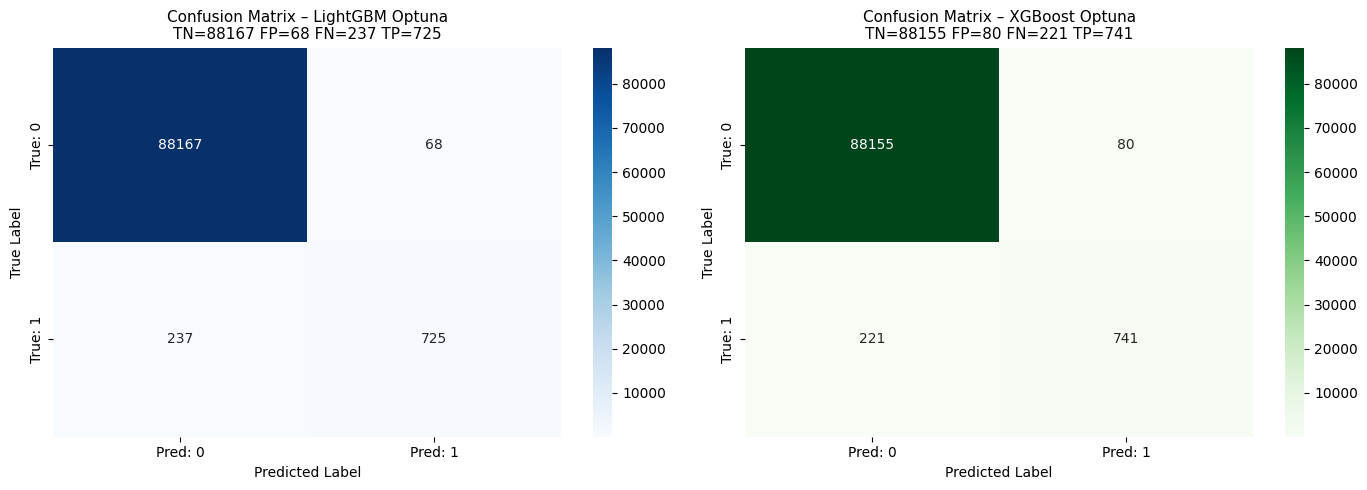

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, name, preds, cmap in [
    (axes[0], "LightGBM Optuna", lgb_opt_test_preds, "Blues"),
    (axes[1], "XGBoost Optuna",  xgb_opt_test_preds, "Greens"),
]:
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap=cmap,
        xticklabels=["Pred: 0", "Pred: 1"],
        yticklabels=["True: 0", "True: 1"],
        ax=ax,
    )
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"Confusion Matrix – {name}\nTN={tn} FP={fp} FN={fn} TP={tp}", fontsize=11)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()

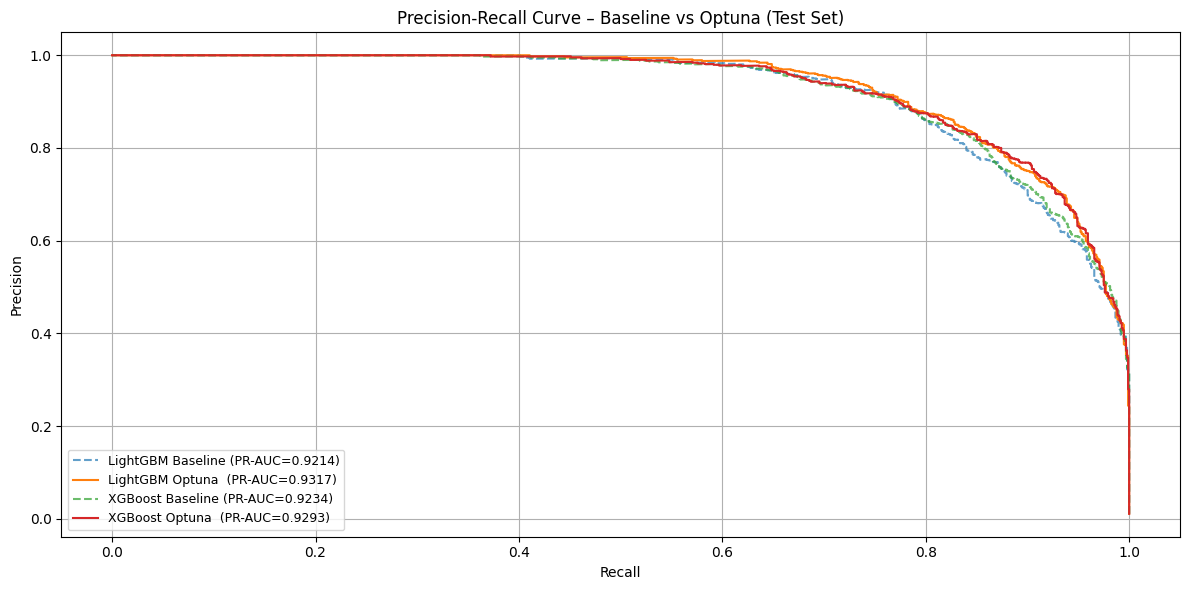

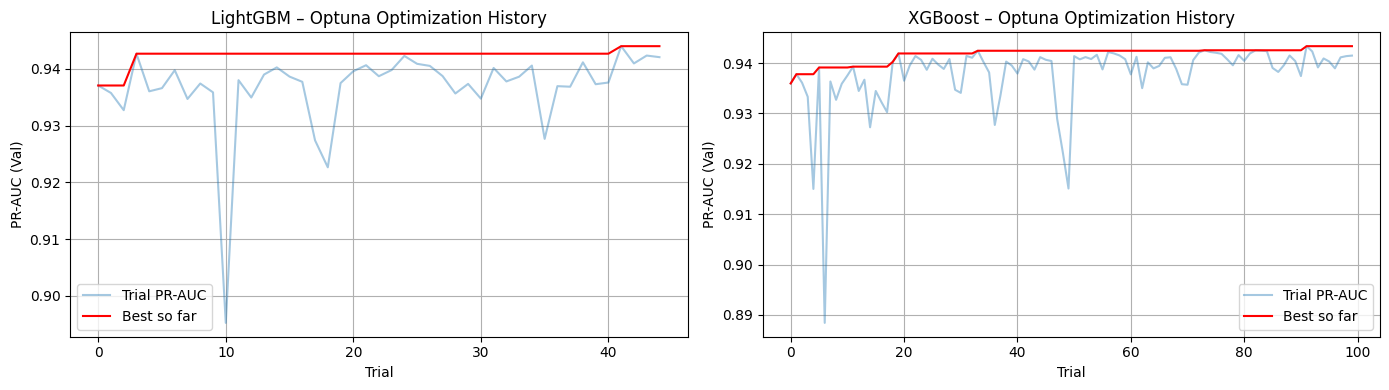

In [33]:
# Precision-Recall Curve – so sánh Baseline vs Optuna
plt.figure(figsize=(12, 6))

for model_name, probs_base, probs_opt in [
    ("LightGBM", lgb_test_probs, lgb_opt_test_probs),
    ("XGBoost",  xgb_test_probs, xgb_opt_test_probs),
]:
    prec_b, rec_b, _ = precision_recall_curve(y_test, probs_base)
    prec_o, rec_o, _ = precision_recall_curve(y_test, probs_opt)
    auc_b = average_precision_score(y_test, probs_base)
    auc_o = average_precision_score(y_test, probs_opt)
    plt.plot(rec_b, prec_b, linestyle="--", label=f"{model_name} Baseline (PR-AUC={auc_b:.4f})", alpha=0.7)
    plt.plot(rec_o, prec_o, linestyle="-",  label=f"{model_name} Optuna  (PR-AUC={auc_o:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve – Baseline vs Optuna (Test Set)")
plt.legend(fontsize=9)
plt.grid(True)
plt.tight_layout()
plt.show()

# Optuna optimization history
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, study, name in [
    (axes[0], lgb_study, "LightGBM"),
    (axes[1], xgb_study, "XGBoost"),
]:
    values = [t.value for t in study.trials if t.value is not None]
    best_so_far = pd.Series(values).cummax()
    ax.plot(values, alpha=0.4, label="Trial PR-AUC")
    ax.plot(best_so_far.values, color="red", label="Best so far")
    ax.set_title(f"{name} – Optuna Optimization History")
    ax.set_xlabel("Trial")
    ax.set_ylabel("PR-AUC (Val)")
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

## 11. Loss Curve


c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\valida

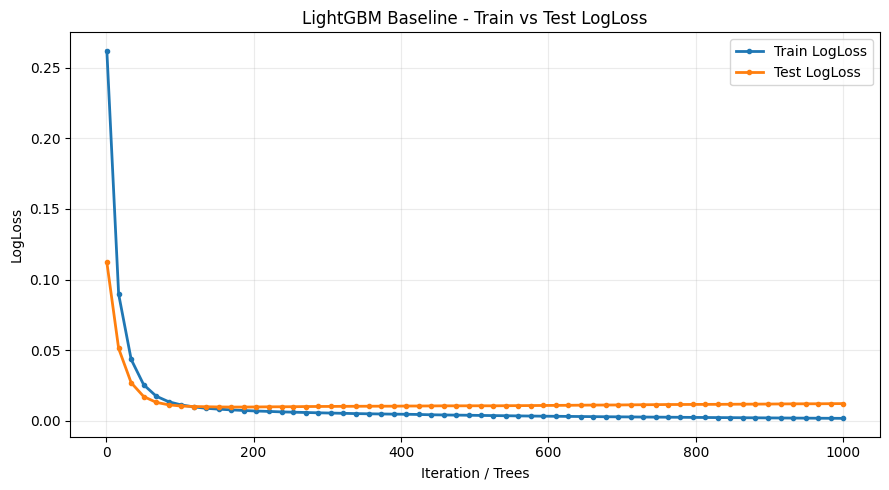

,step,train_loss,test_loss
50,847,0.002223,0.011692
51,864,0.002153,0.011759
52,881,0.002103,0.011793
53,898,0.002042,0.011845
54,915,0.001984,0.011923
55,932,0.001929,0.011991
56,949,0.001871,0.012028
57,966,0.001814,0.012038
58,983,0.001768,0.012117
59,1000,0.001730,0.012151


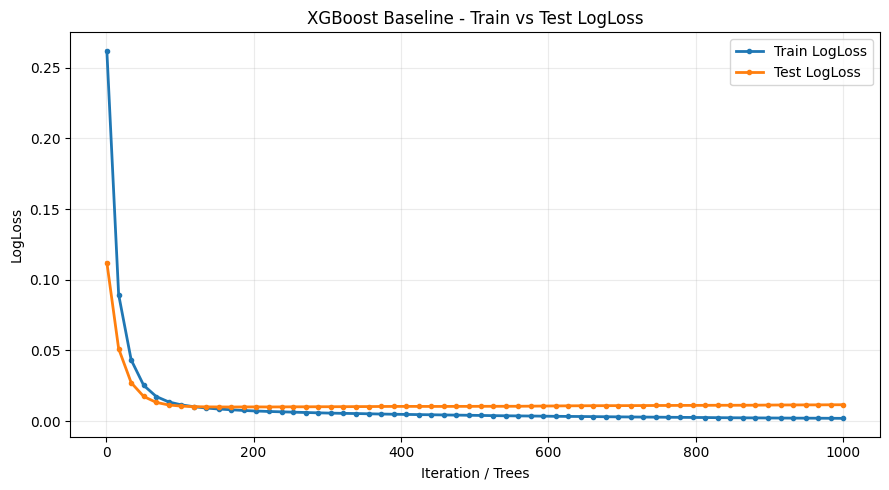

,step,train_loss,test_loss
50,847,0.002336,0.011168
51,864,0.002286,0.011190
52,881,0.002233,0.011233
53,898,0.002183,0.011310
54,915,0.002133,0.011370
55,932,0.002085,0.011403
56,949,0.002051,0.011444
57,966,0.002016,0.011448
58,983,0.001965,0.011515
59,1000,0.001924,0.011541


c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\valida

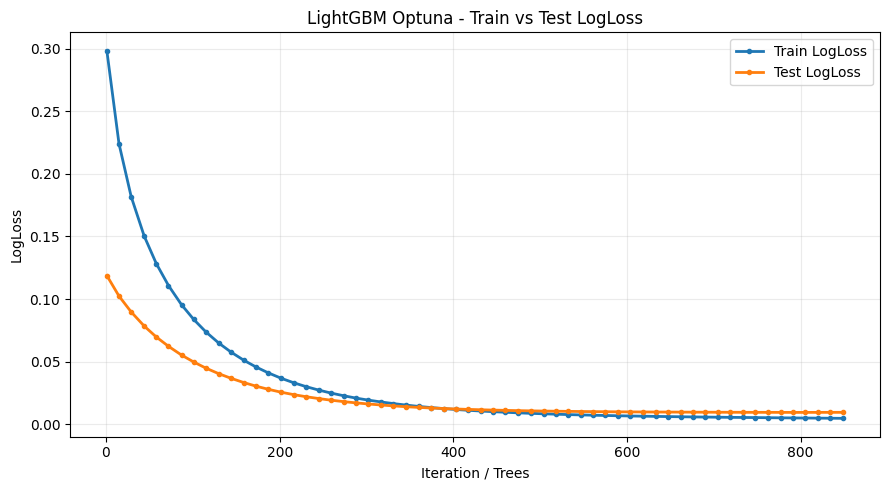

,step,train_loss,test_loss
50,719,0.005525,0.009571
51,734,0.005426,0.009552
52,748,0.005338,0.009525
53,762,0.005244,0.009517
54,777,0.005147,0.009486
55,791,0.005058,0.009481
56,805,0.004979,0.009481
57,820,0.004901,0.009495
58,834,0.004817,0.009509
59,849,0.004732,0.009515


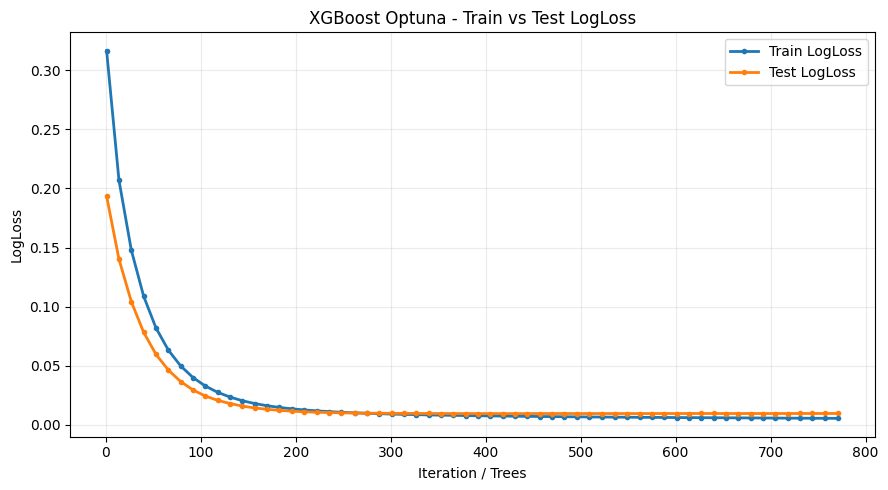

,step,train_loss,test_loss
50,653,0.006021,0.009654
51,666,0.005968,0.009655
52,679,0.005912,0.009652
53,692,0.005863,0.009639
54,705,0.005798,0.009658
55,718,0.005737,0.009652
56,731,0.005690,0.009668
57,744,0.005653,0.009666
58,757,0.005607,0.009690
59,771,0.005567,0.009688


In [34]:
# Dùng sample để plot nhanh hơn, tránh notebook chạy quá nặng
X_train_loss, y_train_loss = sample_xy(X_train_res, y_train_res, max_samples=30000)
X_test_loss, y_test_loss = sample_xy(X_test, y_test, max_samples=20000)


def lgbm_loss_curve(model, X_train_eval, y_train_eval, X_test_eval, y_test_eval, max_points=60):
    total_steps = int(getattr(model, "best_iteration_", None) or model.n_estimators_)
    checkpoints = build_checkpoints(total_steps, max_points=max_points)
    rows = []

    for step in checkpoints:
        train_prob = np.clip(model.predict_proba(X_train_eval, num_iteration=step)[:, 1], 1e-6, 1 - 1e-6)
        test_prob = np.clip(model.predict_proba(X_test_eval, num_iteration=step)[:, 1], 1e-6, 1 - 1e-6)
        rows.append({
            "step": step,
            "train_loss": log_loss(y_train_eval, train_prob),
            "test_loss": log_loss(y_test_eval, test_prob),
        })

    return pd.DataFrame(rows)


def xgb_loss_curve(model, X_train_eval, y_train_eval, X_test_eval, y_test_eval, max_points=60):
    total_steps = int(model.get_booster().num_boosted_rounds())
    checkpoints = build_checkpoints(total_steps, max_points=max_points)
    rows = []

    for step in checkpoints:
        train_prob = np.clip(model.predict_proba(X_train_eval, iteration_range=(0, step))[:, 1], 1e-6, 1 - 1e-6)
        test_prob = np.clip(model.predict_proba(X_test_eval, iteration_range=(0, step))[:, 1], 1e-6, 1 - 1e-6)
        rows.append({
            "step": step,
            "train_loss": log_loss(y_train_eval, train_prob),
            "test_loss": log_loss(y_test_eval, test_prob),
        })

    return pd.DataFrame(rows)


lgb_baseline_loss = lgbm_loss_curve(lgb_model, X_train_loss, y_train_loss, X_test_loss, y_test_loss)
plot_loss_curve(lgb_baseline_loss, "LightGBM Baseline - Train vs Test LogLoss")

xgb_baseline_loss = xgb_loss_curve(xgb_model, X_train_loss, y_train_loss, X_test_loss, y_test_loss)
plot_loss_curve(xgb_baseline_loss, "XGBoost Baseline - Train vs Test LogLoss")

lgb_optuna_loss = lgbm_loss_curve(lgb_best, X_train_loss, y_train_loss, X_test_loss, y_test_loss)
plot_loss_curve(lgb_optuna_loss, "LightGBM Optuna - Train vs Test LogLoss")

xgb_optuna_loss = xgb_loss_curve(xgb_best, X_train_loss, y_train_loss, X_test_loss, y_test_loss)
plot_loss_curve(xgb_optuna_loss, "XGBoost Optuna - Train vs Test LogLoss")


## 12. SHAP Test


c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


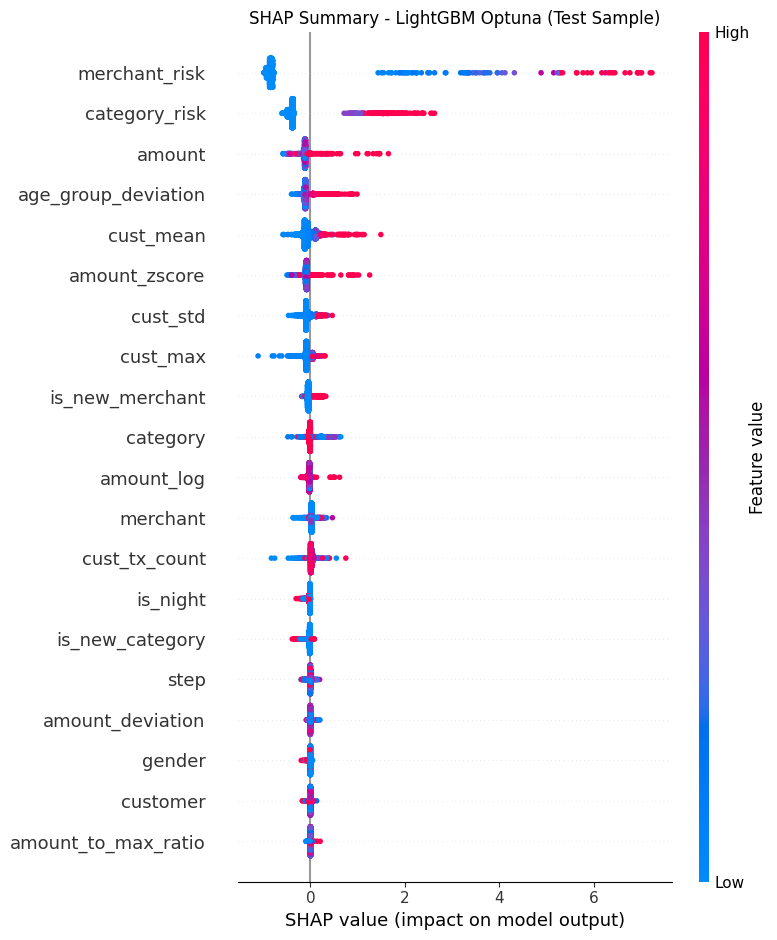

Top 20 features by mean(|SHAP|) - LightGBM Optuna:


,feature,mean_abs_shap
0,merchant_risk,0.972586
1,category_risk,0.508469
2,amount,0.132318
3,age_group_deviation,0.129430
4,cust_mean,0.121455
5,amount_zscore,0.099841
6,cust_std,0.091945
7,cust_max,0.082163
8,is_new_merchant,0.074073
9,category,0.045286


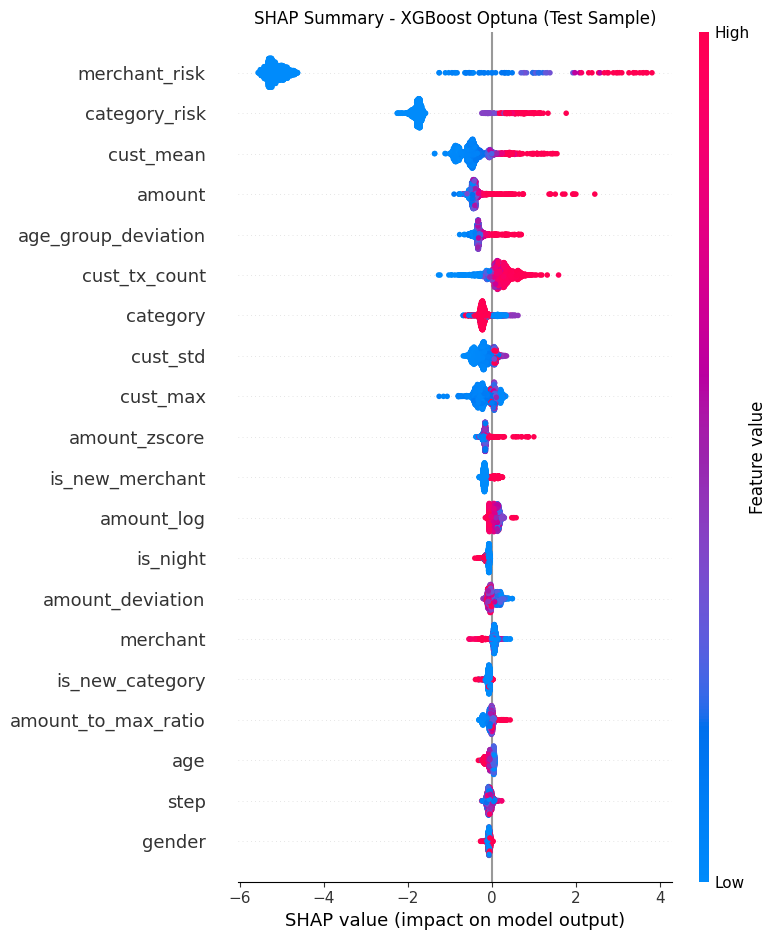

Top 20 features by mean(|SHAP|) - XGBoost Optuna:


,feature,mean_abs_shap
0,merchant_risk,5.003740
1,category_risk,1.661116
2,cust_mean,0.528404
3,amount,0.430994
4,age_group_deviation,0.319516
5,cust_tx_count,0.273342
6,category,0.221155
7,cust_std,0.219776
8,cust_max,0.203799
9,amount_zscore,0.169839


In [35]:
plot_shap_test(lgb_best, X_test, "LightGBM Optuna")
plot_shap_test(xgb_best, X_test, "XGBoost Optuna")


## 11. Feature Importance

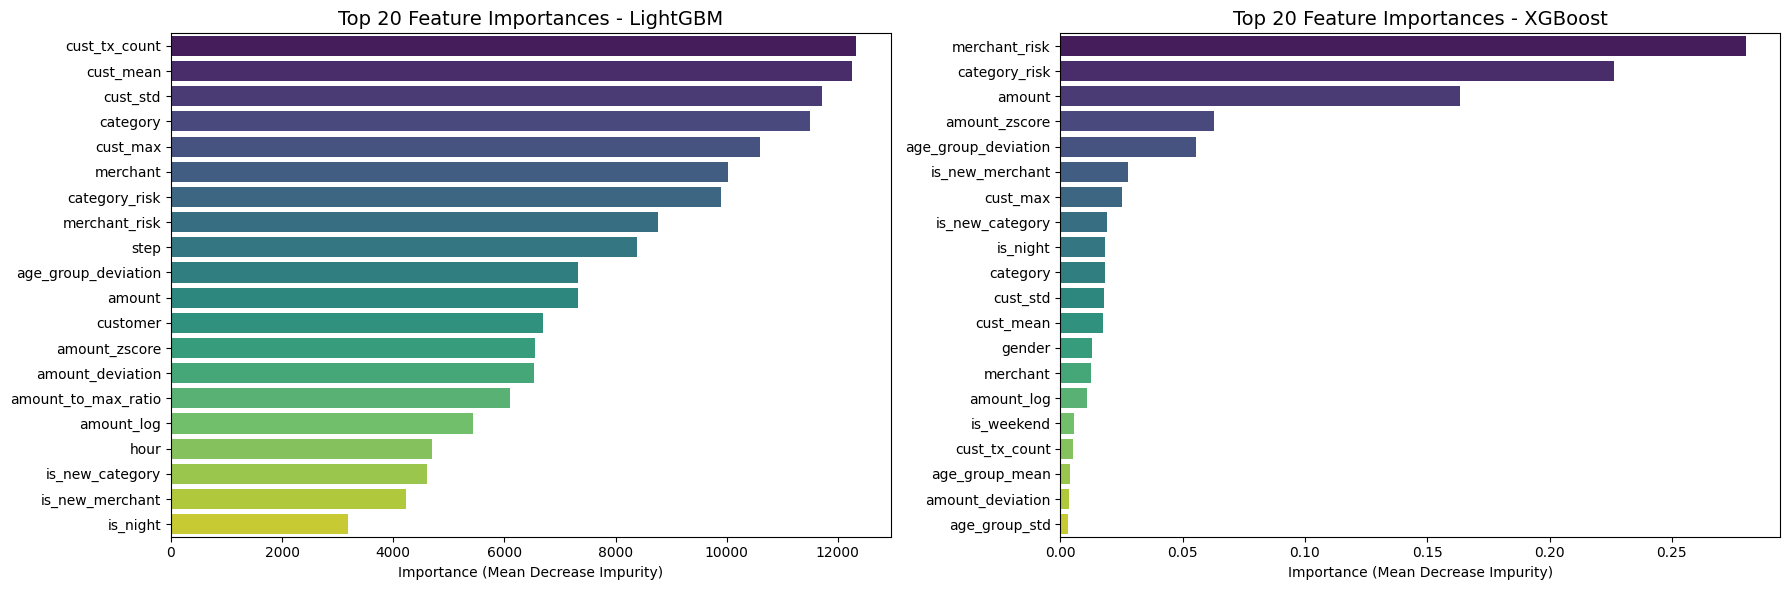


Top 20 most important features - LightGBM:
            feature  importance
      cust_tx_count       12332
          cust_mean       12257
           cust_std       11718
           category       11499
           cust_max       10604
           merchant       10024
      category_risk        9894
      merchant_risk        8770
               step        8383
age_group_deviation        7331
             amount        7323
           customer        6699
      amount_zscore        6545
   amount_deviation        6534
amount_to_max_ratio        6098
         amount_log        5436
               hour        4706
    is_new_category        4602
    is_new_merchant        4228
           is_night        3193

Top 20 most important features - XGBoost:
            feature  importance
      merchant_risk    0.280254
      category_risk    0.226329
             amount    0.163389
      amount_zscore    0.062969
age_group_deviation    0.055455
    is_new_merchant    0.027523
           cust_m

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for ax, model, name in [
    (axes[0], lgb_best, "LightGBM"),
    (axes[1], xgb_best, "XGBoost"),
]:
    importance_df = pd.DataFrame({
        'feature': feature_cols,
        'importance': model.feature_importances_
    }).sort_values('importance', ascending=False).reset_index(drop=True)

    top_df = importance_df.head(20)

    sns.barplot(
        data=top_df, x='importance', y='feature',
        hue='feature', palette='viridis', legend=False, ax=ax
    )
    ax.set_title(f'Top 20 Feature Importances - {name}', fontsize=14)
    ax.set_xlabel('Importance (Mean Decrease Impurity)')
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

# Print the top 20 features for each model
for model, name in [
    (lgb_best, "LightGBM"),
    (xgb_best, "XGBoost"),
]:
    importance_df = pd.DataFrame({
        'feature': feature_cols,
        'importance': model.feature_importances_
    }).sort_values('importance', ascending=False).reset_index(drop=True)

    print(f"\nTop 20 most important features - {name}:")
    print(importance_df.head(20).to_string(index=False))


In [37]:
MODEL_DIR = os.path.abspath(os.path.join(DATA_PATH, '..', 'models'))
os.makedirs(MODEL_DIR, exist_ok=True)

lgb_model_path = os.path.join(MODEL_DIR, 'lgb_best.pkl')
xgb_model_path = os.path.join(MODEL_DIR, 'xgb_best.pkl')

joblib.dump(lgb_best, lgb_model_path)
joblib.dump(xgb_best, xgb_model_path)

print(f"LightGBM model saved to: {lgb_model_path}")
print(f"XGBoost model saved to: {xgb_model_path}")

LightGBM model saved to: D:\AI66A_group_10_Topic_7\src\data\models\lgb_best.pkl
XGBoost model saved to: D:\AI66A_group_10_Topic_7\src\data\models\xgb_best.pkl
